# NB 03 Calibration of the weight decay and of the marginal-uniformity penalty weight (C-CODINE and C-CopFlow)

C-CODINE and C-CopFlow are trained with the penalty lambda * sum_i integral (integral c du_{-i} - 1)^2 du_i on the margins of the fitted copula density (Aich & Aich, 2025, eq. 1). This notebook chooses the weight decay of the three network groups (stage 1: C-CODINE, C-CopFlow with affine coupling, C-CopFlow with spline coupling) and then lambda (stage 2), both once per group and tuned on the whole mix of ten designs, with the chosen weight decays in force. It runs after NB00 to NB02 and before NB04 and the synthetic notebooks, which read both from `margin_penalty_calibrated.json` in the artifact folder. The design below describes stage 2; stage 1 is described at its start.

**Design.**
* All ten synthetic designs (`synthetic_study.DGPS`), one fresh data draw each (seeds that differ from the draws used in the AAA notebooks), sample sizes assigned to the designs by a fixed random permutation of `N_LIST`, one training seed.
* Three groups, one variant each (w only): C-CODINE; C-CopFlow with affine coupling; C-CopFlow with rational-quadratic spline coupling. Every design gives one cell per group, 10 per group in total. The chosen values are used for all variants of the group, on every synthetic design and on the real data.
* Penalty weights `LAMBDAS` (0 is the unconstrained reference). Data and seed are identical across weights.
* **Margins that are not exactly uniform.** The synthetic pseudo-observations are first distorted by a monotone, w-dependent power transform u' = u^a(w), a(w) = exp(+-delta (2 w~ - 1)) (opposite sign for the two margins). A monotone transform leaves the copula unchanged, so the true copula remains the exact oracle for the excess CVPE, while the networks see margins that are not uniform given w, as in the real data. delta is calibrated so that the mean Kolmogorov-Smirnov distance of the pseudo-observations to U(0,1) within eight equal-count bins of w equals that of the training rows of the four real folds; `DELTA_MIN` is a lower bound so that the calibration always tests non-uniform margins. The out-of-sample points used to score the fits are not distorted.

**Rule.** In every cell (design x variant) the best weight is the one with the lowest excess CVPE over the grid. For each group the chosen weight is the median of the 10 best weights (the lower median, so that the result is a grid value; the mode is printed as a diagnostic). That weight is used for all variants of the family in the rest of the code. The one-standard-error rule on the mean log excess ratio and the margin error of the fitted densities are printed as diagnostics and do not change the choice.

**Limits.** One training seed per cell; only the w-only variant of each group; the ten designs and the calibrated distortion only. The synthetic notebooks use the same design families (other draws), so their penalised networks are slightly favoured; the real-data results are not.

**Cost.** Stage 1: 5 weight decays x 3 groups x 10 designs = 150 trainings; stage 2: 5 weights x 3 groups x 10 designs = 150 trainings; sizes between 300 and 2,000 (mean 1,070).

## Imports and settings

In [1]:
import os, dataclasses, json
os.environ["OMP_NUM_THREADS"] = "1"; os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"; os.environ["NUMEXPR_NUM_THREADS"] = "1"
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from scipy.stats import kstest
from IPython.display import display

import plotting_core
import reporting_tables as RT
# Unconditional models / penalty calibration do not use previously calibrated network weights.
os.environ["THESIS_ALLOW_UNCALIBRATED_IMPORT"] = "1"
import fold_pipeline as FP
import synthetic_study as S
import synthetic_report as R
from run_support import save_artifact, SMOKE, MAX_WORKERS, ARTIFACT_DIR

NOTEBOOK = "03_marginal_uniformity_penalty_calibration"
plotting_core.configure(NOTEBOOK)
RT.configure(NOTEBOOK)

N_LIST = [300, 2000, 800, 1000, 1700, 900, 1200, 400, 600, 1800]
DESIGNS = list(S.DGPS)                                    # the ten designs
N_OF = dict(zip(DESIGNS, np.random.default_rng(2026).permutation(N_LIST).tolist()))
DATA_SEED0 = 10_000                                       # the AAA notebooks use S.DATA_SEED + rep
_lam = os.environ.get("THESIS_CAL_LAMBDAS")
LAMBDAS = tuple(float(x) for x in _lam.split(",")) if _lam else ((0.0, 10.0) if SMOKE else (0.0, 3.0, 10.0, 30.0, 100.0))
assert 0.0 in LAMBDAS and len(set(LAMBDAS)) == len(LAMBDAS)
_wds = os.environ.get("THESIS_CAL_WDS")
WD_LIST = tuple(float(x) for x in _wds.split(",")) if _wds else ((0.0, 1e-2) if SMOKE else tuple(FP.WD_GRID))
assert 0.0 in WD_LIST and len(set(WD_LIST)) == len(WD_LIST)
# One variant per group (w only): the weight decay and the penalty weight are tuned once, on the ten designs, and reused unchanged
# for all variants of the group, on every synthetic design and on the real data.
GROUP = {"C-CODINE (w only)": "C-CODINE", "C-CopFlow (w only, affine)": "C-CopFlow, affine",
         "C-CopFlow (w only, spline coupling)": "C-CopFlow, spline coupling"}
MODELS = WD_MODELS = list(GROUP)
if SMOKE:                                                  # plumbing test only
    DESIGNS = DESIGNS[:2]; N_OF = {d: 300 for d in DESIGNS}
N_OOS = 300 if SMOKE else S.N_OOS
DELTA_MIN = 0.10
BATCH = FP.BATCH_DIR / "penalty_calibration"
print("designs and training sizes:", N_OF)
print("weight decays:", WD_LIST, "| models:", WD_MODELS, "| trainings:", len(WD_LIST) * len(WD_MODELS) * len(DESIGNS))
print("penalty weights:", LAMBDAS, "| models:", MODELS, "| trainings:", len(LAMBDAS) * len(MODELS) * len(DESIGNS))

designs and training sizes: {'3a': 2000, '3b': 1800, '3c': 300, '3d': 1200, '3e': 600, '3f': 1000, '3g': 900, '3h': 800, '3i': 400, '3j': 1700}
weight decays: (0.0, 0.0001, 0.001, 0.01, 0.1) | models: ['C-CODINE (w only)', 'C-CopFlow (w only, affine)', 'C-CopFlow (w only, spline coupling)'] | trainings: 150
penalty weights: (0.0, 3.0, 10.0, 30.0, 100.0) | models: ['C-CODINE (w only)', 'C-CopFlow (w only, affine)', 'C-CopFlow (w only, spline coupling)'] | trainings: 150


## Strength of the margin distortion, calibrated on the real folds

The statistic is the mean over the eight equal-count bins of w and the two margins of the KS distance of the pseudo-observations to U(0,1), on the training rows of each real fold. For a given delta the same statistic is computed on independent uniforms with the real fold's covariate, distorted with that delta, and delta is found by bisection. If the real margins are no further from uniform than independent uniforms, the calibration gives delta = 0 and `DELTA_MIN` applies.

In [2]:
W_LO, W_HI = S.W_RANGE

def distort(u, wt, delta, sign):
    """Monotone, w-dependent power transform u^a(w) with a(w) = exp(sign * delta * (2 wt - 1)).

    Parameters:
    u (np.ndarray): Pseudo-observations in (0, 1).
    wt (np.ndarray): Covariate rescaled to [0, 1].
    delta (float): Strength.
    sign (float): +1 or -1.

    Returns:
    np.ndarray: Distorted pseudo-observations.
    """
    return np.clip(np.asarray(u, float) ** np.exp(sign * delta * (2.0 * np.asarray(wt, float) - 1.0)), 1e-6, 1 - 1e-6)

def bin_ks(u1, u2, w, n_bins=8):
    """Mean KS distance to U(0,1) of both margins within equal-count bins of w.

    Parameters:
    u1 (np.ndarray): First pseudo-observation.
    u2 (np.ndarray): Second pseudo-observation.
    w (np.ndarray): Covariate.
    n_bins (int): Number of bins. Default 8.

    Returns:
    float: The mean KS distance.
    """
    order = np.argsort(w, kind="stable")
    return float(np.mean([kstest(u[idx], "uniform").statistic for idx in np.array_split(order, n_bins) for u in (u1, u2)]))

_env = os.environ.get("THESIS_CAL_DELTA")
REAL = None
try:
    ARR = FP.load_all_folds()
except (FileNotFoundError, KeyError, ValueError) as exc:
    if _env is None:
        raise RuntimeError("Notebook 03 requires all real-data folds to calibrate the distortion; "
                           "run notebook 00 or supply THESIS_CAL_DELTA explicitly") from exc
    print("real folds not available; using explicit THESIS_CAL_DELTA:", exc)
else:
    REAL = []
    for f, A in ARR.items():
        m = np.asarray(A["train"], bool)
        REAL.append((np.asarray(A["u1"])[m], np.asarray(A["u2"])[m], np.asarray(A["w"], float)[m]))
    if len(REAL) != 4 or any(len(r[0]) < 20 for r in REAL):
        raise ValueError("Expected four nonempty real-data training folds for penalty calibration")
    print("real folds loaded:", [len(r[0]) for r in REAL])

def sim_ks(delta, reps=3):
    """Mean binned KS of distorted independent uniforms with the covariate of each real training fold.

    Parameters:
    delta (float): Distortion strength passed to distort.
    reps (int): Number of simulated draws per real training fold. Default 3.

    Returns:
    float: Mean of the binned KS statistic over the folds and draws.
    """
    out = []
    for k, (u1, u2, w) in enumerate(REAL):
        rng = np.random.default_rng(k)
        wt = (np.argsort(np.argsort(w)) + 0.5) / len(w)
        for _ in range(reps):
            out.append(bin_ks(distort(rng.uniform(size=len(w)), wt, delta, +1), distort(rng.uniform(size=len(w)), wt, delta, -1), w))
    return float(np.mean(out))

REAL_KS = float(np.mean([bin_ks(*r) for r in REAL])) if REAL is not None else np.nan
if _env is not None:
    DELTA_CAL = float(_env)
    if not np.isfinite(DELTA_CAL) or DELTA_CAL < 0:
        raise ValueError("THESIS_CAL_DELTA must be finite and nonnegative")
else:
    if not np.isfinite(REAL_KS):
        raise ValueError("The real-fold binned KS target must be finite")
    lo, hi = 0.0, 1.5
    if sim_ks(0.0) >= REAL_KS:
        DELTA_CAL = 0.0
    else:
        for _ in range(14):
            mid = 0.5 * (lo + hi)
            lo, hi = (mid, hi) if sim_ks(mid) < REAL_KS else (lo, mid)
        DELTA_CAL = 0.5 * (lo + hi)
DELTA = max(DELTA_CAL, DELTA_MIN)
print(f"real mean binned KS {REAL_KS:.4f} | calibrated delta {DELTA_CAL:.3f} | delta used {DELTA:.3f}")
if REAL is not None:
    print(f"binned KS of uniforms: no distortion {sim_ks(0.0):.4f}, delta used {sim_ks(DELTA):.4f}")

real folds loaded: [1394, 1393, 1345, 1345]
real mean binned KS 0.0639 | calibrated delta 0.000 | delta used 0.100


binned KS of uniforms: no distortion 0.0680, delta used 0.0710


## Stage 1: weight decay of the three network groups

The weight decay is chosen before the penalty weight, because the penalty weight is calibrated with the chosen weight decay in force.

* **Groups.** C-CODINE; C-CopFlow with affine coupling; C-CopFlow with rational-quadratic spline coupling. Each group is represented by its w-only variant, so every group has 10 cells (one per design). The value chosen is used for every variant of the group.
* **Data.** The same ten designs and the same distortion of the margins as in the penalty stage, but fresh draws (other seeds) and other sample sizes: each design receives the training size that the penalty stage gave to the next design. One training seed, penalty off.
* **Rule.** In every cell the best weight decay is the one with the lowest excess CVPE over the oracle on the grid `WD_LIST` (ties use the smaller value). The chosen value of a group is the lower median of its 10 best values (so it is a grid value). The mode is printed as a diagnostic; if it differs from the median, the counts are bimodal and should be read before the choice is accepted.
* **Limits.** One training seed per cell; the penalty is off in this stage but on in the study, so the two regularisers interact in a way this sequential calibration does not capture; the optimum can lie at the edge of the grid (a note is printed; extend with `THESIS_CAL_WDS`).

In [3]:
# Fresh draws and other sample sizes than the penalty stage (the weight decay is not chosen on the data that choose lambda).
DATA_SEED_WD = 20_000
N_OF_WD = {d: N_OF[DESIGNS[(k + 1) % len(DESIGNS)]] for k, d in enumerate(DESIGNS)}
BUNDLES_WD = {}
for k, d in enumerate(DESIGNS):
    b = S.make_bundle(d, n_train=N_OF_WD[d], n_oos=N_OOS, data_seed=DATA_SEED_WD + k, rep=0)
    wt = (np.asarray(b["w"], float) - W_LO) / (W_HI - W_LO)
    BUNDLES_WD[d] = dict(b, u1=distort(b["u1"], wt, DELTA, +1), u2=distort(b["u2"], wt, DELTA, -1))
ORACLE_WD = {d: np.asarray(BUNDLES_WD[d]["oracle_loss"], float) for d in DESIGNS}
print("training sizes of the weight-decay stage:", N_OF_WD)

WD_OUT = {}
for wd in WD_LIST:
    jobs = []
    for d in DESIGNS:
        for j in S.build_neural_synth_jobs([BUNDLES_WD[d]], {m: wd for m in FP.NEURAL_MODELS}, seeds=(0,), smoke=SMOKE):
            if j["model"] in WD_MODELS:
                jobs.append(dataclasses.replace(j, hyper=dict(j["hyper"], margin_penalty=0.0)))
    bd = BATCH / f"weight_decay_{wd:g}"
    bd.mkdir(parents=True, exist_ok=True)
    with R.quiet():
        WD_OUT[wd] = FP.run_batch(jobs, max_workers=MAX_WORKERS, batch_dir=bd, fn=S.neural_synth_job, key_fn=S.synth_key, desc=f"weight decay={wd:g}")
    print(f"weight decay = {wd:g}: {len(WD_OUT[wd])} of {len(jobs)} trainings")

training sizes of the weight-decay stage: {'3a': 1800, '3b': 300, '3c': 1200, '3d': 600, '3e': 1000, '3f': 900, '3g': 800, '3h': 400, '3i': 1700, '3j': 2000}


weight decay = 0: 30 of 30 trainings


weight decay = 0.0001: 30 of 30 trainings


weight decay = 0.001: 30 of 30 trainings


weight decay = 0.01: 30 of 30 trainings


weight decay = 0.1: 30 of 30 trainings


## Best weight decay per cell, and the value used downstream

best_wd,0.0000,0.0001,0.0010,0.0100,0.1000
group,,,,,
C-CODINE,2,1,5,1,1
"C-CopFlow, affine",0,1,2,6,1
"C-CopFlow, spline coupling",0,1,1,3,5


,,median best weight decay
group,model,
C-CODINE,C-CODINE (w only),0.001
"C-CopFlow, affine","C-CopFlow (w only, affine)",0.010
"C-CopFlow, spline coupling","C-CopFlow (w only, spline coupling)",0.055


chosen weight decays (lower median of the best values per cell): {'C-CODINE': 0.001, 'C-CopFlow, affine': 0.01, 'C-CopFlow, spline coupling': 0.01}
mode of the best values (diagnostic): {'C-CODINE': 0.001, 'C-CopFlow, affine': 0.01, 'C-CopFlow, spline coupling': 0.1}
NOTE: median and mode differ for C-CopFlow, spline coupling: read the counts above before accepting the choice.


mean      sd   n      se  best_epoch
group                      wd                                            
C-CODINE                   0.0000  0.0000  0.0000  10  0.0000       530.0
                           0.0001 -0.0941  0.1886  10  0.0597       490.0
                           0.0010 -0.3736  0.3776  10  0.1194       620.0
                           0.0100 -0.0453  0.6386  10  0.2019       340.0
                           0.1000  1.2103  1.8266  10  0.5776       100.0
C-CopFlow, affine          0.0000  0.0000  0.0000  10  0.0000       270.0
                           0.0001 -0.2883  0.3223  10  0.1019       140.0
                           0.0010 -0.4104  0.3471  10  0.1098       340.0
                           0.0100 -0.5920  0.4262  10  0.1348       360.0
                           0.1000 -0.1370  0.8037  10  0.2542       760.0
C-CopFlow, spline coupling 0.0000  0.0000  0.0000  10  0.0000       170.0
                           0.0001  0.0277  0.1474  10  0.0466       170.0
                           0.0010 -0.1211  0.1984  10  0.0627       150.0
                           0.0100 -0.4870  0.5037  10  0.1593       300.0
                           0.1000 -0.5568  1.3079  10  0.4136       400.0

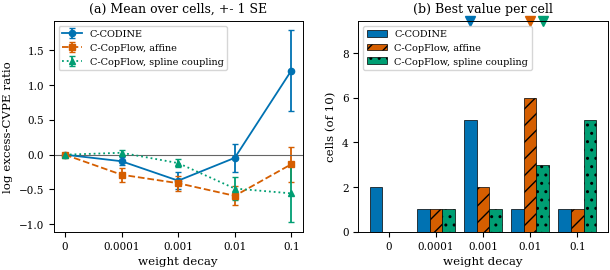

In [4]:
rows = []
for wd in WD_LIST:
    for key, r in WD_OUT[wd].items():
        d = key.split("__")[0]
        rows.append(dict(dgp=d, n=N_OF_WD[d], wd=wd, model=r["model"], group=GROUP[r["model"]],
                         excess_cvpe=float(np.mean(r["loss_oos"] - ORACLE_WD[d])), margin_ks_max=float(np.max(r["margin_ks"])),
                         best_epoch=r["best_epoch"], runtime=r["runtime"]))
WDLONG = pd.DataFrame(rows).sort_values(["group", "model", "dgp", "wd"]).reset_index(drop=True)
RT.write_table(WDLONG, "weight_decay_calibration_long", index=False,
               caption="Weight-decay calibration: excess CVPE, largest marginal KS distance, best epoch and runtime of every network, design and weight decay.")
if not np.isfinite(WDLONG.excess_cvpe).all():
    raise ValueError("Non-finite excess CVPE in the weight-decay calibration; cannot select")
if WDLONG.duplicated(["group", "model", "dgp", "wd"]).any():
    raise ValueError("Duplicate weight-decay calibration cell")
if (WDLONG.groupby(["group", "model", "dgp"]).size() != len(WD_LIST)).any():
    raise ValueError("Incomplete weight-decay grid: some design/model cells are missing values")
best_wd = (WDLONG.sort_values(["group", "model", "dgp", "excess_cvpe", "wd"]).groupby(["group", "model", "dgp"], as_index=False).first()
           [["group", "model", "dgp", "n", "wd"]].rename(columns={"wd": "best_wd"}))
RT.write_table(best_wd, "weight_decay_calibration_best_per_cell", index=False,
               caption="Best weight decay in each design and network cell (stage 1).")
if (best_wd.groupby("group").size() != len(DESIGNS)).any():
    raise ValueError("Expected one complete cell per design in every weight-decay group")
CHOSEN_WD = {g: float(np.sort(v.best_wd.values)[(len(v) - 1) // 2]) for g, v in best_wd.groupby("group")}
MODE_WD = {g: float(min(v.best_wd.mode())) for g, v in best_wd.groupby("group")}
display(pd.crosstab(best_wd.group, best_wd.best_wd))
display(best_wd.groupby(["group", "model"]).best_wd.median().rename("median best weight decay").to_frame())
print("chosen weight decays (lower median of the best values per cell):", CHOSEN_WD)
print("mode of the best values (diagnostic):", MODE_WD)
for g, v in CHOSEN_WD.items():
    if v == max(WD_LIST):
        print(f"NOTE: the median best weight decay of {g} is the largest value tried; extend THESIS_CAL_WDS.")
    if MODE_WD[g] != v:
        print(f"NOTE: median and mode differ for {g}: read the counts above before accepting the choice.")
WDLONG["exc"] = WDLONG.excess_cvpe.clip(lower=1e-5)          # floor only for the log-ratio diagnostic, never for the selection
ref = WDLONG[WDLONG.wd == 0.0].set_index(["model", "dgp"]).exc
WDLONG["log_ratio"] = np.log(WDLONG.exc.values / ref.loc[list(zip(WDLONG.model, WDLONG.dgp))].values)
G_WD = WDLONG.groupby(["group", "wd"]).log_ratio.agg(mean="mean", sd="std", n="count")
G_WD["se"] = G_WD.sd / np.sqrt(G_WD.n)
G_WD["best_epoch"] = WDLONG.groupby(["group", "wd"]).best_epoch.mean()
display(G_WD.round(4))
import figure_recipes as FR
FR.weight_decay_calibration(G_WD, best_wd, WD_LIST, CHOSEN_WD)

## Stage 2: the penalty weight, with the chosen weight decays in force

## Data: ten designs, distorted training margins, clean out-of-sample draw and oracle

In [5]:
BUNDLES, ORACLE = {}, {}
for k, d in enumerate(DESIGNS):
    b = S.make_bundle(d, n_train=N_OF[d], n_oos=N_OOS, data_seed=DATA_SEED0 + k, rep=0)
    wt = (np.asarray(b["w"], float) - W_LO) / (W_HI - W_LO)
    BUNDLES[d] = dict(b, u1=distort(b["u1"], wt, DELTA, +1), u2=distort(b["u2"], wt, DELTA, -1))
    oc = S.oracle_ces(BUNDLES[d], K=32 if SMOKE else 64, G=21 if SMOKE else 81)
    ORACLE[d] = dict(cvpe=np.asarray(b["oracle_loss"], float), ces=float(np.mean(oc["oracle"])), tau=S.tau_true(S.W_EVAL, S.DGPS[d]))
print({d: f"n={N_OF[d]}, oracle CVPE {ORACLE[d]['cvpe'].mean():.4f}" for d in DESIGNS})

{'3a': 'n=2000, oracle CVPE 0.1646', '3b': 'n=1800, oracle CVPE 0.0884', '3c': 'n=300, oracle CVPE 0.1644', '3d': 'n=1200, oracle CVPE 0.0873', '3e': 'n=600, oracle CVPE 0.1650', '3f': 'n=1000, oracle CVPE 0.0894', '3g': 'n=900, oracle CVPE 0.1648', '3h': 'n=800, oracle CVPE 0.0886', '3i': 'n=400, oracle CVPE 0.1651', '3j': 'n=1700, oracle CVPE 0.0898'}


## Training: every design, variant and penalty weight

In [6]:
WD_DEC = {g: CHOSEN_WD[g] for g in CHOSEN_WD}                  # chosen in stage 1
WD = {m: FP.wd_of_model(m, wd_codine=WD_DEC["C-CODINE"], wd_affine=WD_DEC["C-CopFlow, affine"], wd_spline=WD_DEC["C-CopFlow, spline coupling"])
      for m in list(FP.CCODINE_VARIANTS) + list(FP.CCOPFLOW_VARIANTS)}
WD_TAG = "_".join(f"{WD_DEC[g]:g}" for g in ("C-CODINE", "C-CopFlow, affine", "C-CopFlow, spline coupling"))
JOBS = {}
for lam in LAMBDAS:
    JOBS[lam] = []
    for d in DESIGNS:
        for j in S.build_neural_synth_jobs([BUNDLES[d]], WD, seeds=(0,), smoke=SMOKE):
            if j["model"] in MODELS:
                JOBS[lam].append(dataclasses.replace(j, hyper=dict(j["hyper"], margin_penalty=lam)))
OUT, CESO = {}, {}
for lam, jobs in JOBS.items():
    bd = BATCH / f"lambda_{lam:g}_wd_{WD_TAG}"
    bd.mkdir(parents=True, exist_ok=True)
    with R.quiet():
        OUT[lam] = FP.run_batch(jobs, max_workers=MAX_WORKERS, batch_dir=bd, fn=S.neural_synth_job, key_fn=S.synth_key, desc=f"lambda={lam:g}")
        CESO[lam] = S.run_ces_synth(jobs, max_workers=MAX_WORKERS, K=32 if SMOKE else 64, G=21 if SMOKE else 81, batch_dir=bd)
    print(f"lambda = {lam:g}: {len(OUT[lam])} of {len(jobs)} trainings")

lambda = 0: 30 of 30 trainings


lambda = 3: 30 of 30 trainings


lambda = 10: 30 of 30 trainings


lambda = 30: 30 of 30 trainings


lambda = 100: 30 of 30 trainings


## One row per design, variant and penalty weight

In [7]:
rows = []
for lam in LAMBDAS:
    for key, r in OUT[lam].items():
        d = key.split("__")[0]
        b = BUNDLES[d]; tc = b["true_corners"]
        ces = CESO[lam].get(S.ces_synth_key(dict(key=key)))
        ok = ces is not None and ces["status"] == "ok"
        chi = r["chi"]
        rows.append(dict(
            dgp=d, n=N_OF[d], lam=lam, model=r["model"], family=GROUP[r["model"]],
            excess_cvpe=float(np.mean(r["loss_oos"] - ORACLE[d]["cvpe"])),
            excess_ces=float(np.nanmean(ces["es_raw"]) - ORACLE[d]["ces"]) if ok else np.nan,
            tau_rmse=S._curve_rmse(r["tau_curve"], ORACLE[d]["tau"]),
            tail_uu=S._curve_rmse(chi["UU"], tc["UU"]), tail_ll=S._curve_rmse(chi["LL"], tc["LL"]),
            tail_mixed=0.5 * (S._curve_rmse(chi["UL"], tc["UL"]) + S._curve_rmse(chi["LU"], tc["LU"])),
            margin_ks_max=float(np.max(r["margin_ks"])),
            margin_error_grid=float(ces["max_margin_error"]) if ok else np.nan,
            best_epoch=r["best_epoch"], runtime=r["runtime"]))
LONG = pd.DataFrame(rows).sort_values(["family", "model", "dgp", "lam"]).reset_index(drop=True)
RT.write_table(LONG, "penalty_calibration_long", index=False,
               caption="Penalty calibration: excess CVPE and CES, tau and tail RMSE, margin errors, best epoch and runtime of every network, design and penalty weight.")
METRICS = ["excess_cvpe", "excess_ces", "tau_rmse", "tail_uu", "tail_ll", "tail_mixed", "margin_ks_max", "margin_error_grid", "best_epoch", "runtime"]
display(LONG.groupby(["family", "lam"])[METRICS].mean().round(4))

excess_cvpe  excess_ces  tau_rmse  tail_uu  \
family                     lam                                                 
C-CODINE                   0.0         0.0026      0.0013    0.0425   0.1934   
                           3.0         0.0017      0.0003    0.0565   0.1879   
                           10.0        0.0017      0.0003    0.0711   0.1968   
                           30.0        0.0020      0.0004    0.0787   0.1968   
                           100.0       0.0022      0.0004    0.0923   0.2030   
C-CopFlow, affine          0.0         0.0025      0.0011    0.0468   0.1122   
                           3.0         0.0012      0.0005    0.0410   0.0841   
                           10.0        0.0013      0.0005    0.0423   0.0892   
                           30.0        0.0014      0.0005    0.0443   0.0837   
                           100.0       0.0014      0.0005    0.0445   0.0825   
C-CopFlow, spline coupling 0.0         0.0086      0.0017    0.0566   0.0975   
                           3.0         0.0043      0.0009    0.0565   0.0859   
                           10.0        0.0037      0.0006    0.0556   0.0962   
                           30.0        0.0036      0.0006    0.0546   0.1005   
                           100.0       0.0036      0.0006    0.0544   0.0945   

                                  tail_ll  tail_mixed  margin_ks_max  \
family                     lam                                         
C-CODINE                   0.0     0.2306      0.0261         0.0812   
                           3.0     0.2190      0.0262         0.0324   
                           10.0    0.2197      0.0265         0.0239   
                           30.0    0.2234      0.0260         0.0205   
                           100.0   0.2305      0.0255         0.0197   
C-CopFlow, affine          0.0     0.1076      0.0284         0.0777   
                           3.0     0.1036      0.0238         0.0407   
                           10.0    0.1110      0.0280         0.0395   
                           30.0    0.1087      0.0286         0.0380   
                           100.0   0.1102      0.0277         0.0375   
C-CopFlow, spline coupling 0.0     0.1358      0.0333         0.1010   
                           3.0     0.1293      0.0346         0.0574   
                           10.0    0.1196      0.0296         0.0442   
                           30.0    0.1199      0.0293         0.0449   
                           100.0   0.1170      0.0311         0.0494   

                                  margin_error_grid  best_epoch   runtime  
family                     lam                                             
C-CODINE                   0.0               0.0822       730.0   58.5693  
                           3.0               0.0278       950.0   83.0855  
                           10.0              0.0206      1190.0   84.1563  
                           30.0              0.0160      1070.0   81.3400  
                           100.0             0.0153      1210.0   87.6334  
C-CopFlow, affine          0.0               0.0789       360.0  138.4813  
                           3.0               0.0378       560.0  207.9022  
                           10.0              0.0364       730.0  235.0617  
                           30.0              0.0343       540.0  222.1501  
                           100.0             0.0345       700.0  257.8336  
C-CopFlow, spline coupling 0.0               0.1100       580.0  565.7178  
                           3.0               0.0638       370.0  630.8912  
                           10.0              0.0448       520.0  761.7323  
                           30.0              0.0450       500.0  732.4156  
                           100.0             0.0482       490.0  698.8688

## Best weight per cell, and the weight used downstream

The best weight of a cell is the argmin of the **raw**, unfloored excess CVPE over `LAMBDAS` (ties use the smaller weight). The chosen weight of a family is the lower median of its 10 best weights.

In [8]:
FLOOR = 1e-5                                # only used for log-ratio diagnostics, never for lambda selection
if not np.isfinite(LONG.excess_cvpe).all():
    raise ValueError("Non-finite excess CVPE in penalty calibration; cannot select lambda")
if LONG.duplicated(["family", "model", "dgp", "lam"]).any():
    raise ValueError("Duplicate penalty calibration cell/weight")
if (LONG.groupby(["family", "model", "dgp"]).size() != len(LAMBDAS)).any():
    raise ValueError("Incomplete penalty grid: some design/model cells are missing weights")
best = (LONG.sort_values(["family", "model", "dgp", "excess_cvpe", "lam"])
        .groupby(["family", "model", "dgp"], as_index=False).first()
        [["family", "model", "dgp", "n", "lam"]].rename(columns={"lam": "best_lam"}))
RT.write_table(best, "penalty_calibration_best_per_cell", index=False,
               caption="Best penalty weight in each design and network cell (stage 2).")
expected = len(DESIGNS)
if best.groupby("family").size().to_dict() != {g: expected for g in GROUP.values()}:
    raise ValueError(f"Expected {expected} complete design cells per network group")
CHOSEN = {fam: float(np.sort(g.best_lam.values)[(len(g) - 1) // 2]) for fam, g in best.groupby("family")}
print("cells per family:", best.groupby("family").size().to_dict())
display(best.pivot_table(index="dgp", columns="model", values="best_lam"))
display(pd.crosstab(best.family, best.best_lam))
MODE_LAM = {fam: float(min(g.best_lam.mode())) for fam, g in best.groupby("family")}
print("chosen weights (lower median of the best weights per cell):", CHOSEN, "| mode (diagnostic):", MODE_LAM)
for fam, v in CHOSEN.items():
    if MODE_LAM[fam] != v:
        print(f"NOTE: median and mode differ for {fam}: read the counts above before accepting the choice.")
for fam, v in CHOSEN.items():
    if v == 0.0:
        print(f"NOTE: the median best weight of {fam} is 0, so the penalty is switched off for this group.")
    if v == max(LAMBDAS):
        print(f"NOTE: the median best weight of {fam} is the largest weight tried; extend THESIS_CAL_LAMBDAS.")

cells per family: {'C-CODINE': 10, 'C-CopFlow, affine': 10, 'C-CopFlow, spline coupling': 10}


model,C-CODINE (w only),"C-CopFlow (w only, affine)","C-CopFlow (w only, spline coupling)"
dgp,,,
3a,3.0,3.0,100.0
3b,3.0,3.0,10.0
3c,30.0,30.0,30.0
3d,0.0,100.0,100.0
3e,10.0,10.0,30.0
3f,3.0,100.0,3.0
3g,3.0,3.0,100.0
3h,10.0,100.0,100.0
3i,3.0,30.0,100.0


best_lam,0.0,3.0,10.0,30.0,100.0
family,,,,,
C-CODINE,1,5,3,1,0
"C-CopFlow, affine",0,4,1,2,3
"C-CopFlow, spline coupling",0,1,2,2,5


chosen weights (lower median of the best weights per cell): {'C-CODINE': 3.0, 'C-CopFlow, affine': 10.0, 'C-CopFlow, spline coupling': 30.0} | mode (diagnostic): {'C-CODINE': 3.0, 'C-CopFlow, affine': 3.0, 'C-CopFlow, spline coupling': 100.0}
NOTE: median and mode differ for C-CopFlow, affine: read the counts above before accepting the choice.
NOTE: median and mode differ for C-CopFlow, spline coupling: read the counts above before accepting the choice.


## Diagnostics (do not change the choice)

Mean log ratio of the excess CVPE to the unconstrained fit on the same cell, with its standard error; the one-standard-error weight (smallest weight within one SE of the best mean); and the mean margin error of the fitted densities.

In [9]:
LONG["exc"] = LONG.excess_cvpe.clip(lower=FLOOR)
ref = LONG[LONG.lam == 0.0].set_index(["model", "dgp"]).exc
LONG["log_ratio"] = np.log(LONG.exc.values / ref.loc[list(zip(LONG.model, LONG.dgp))].values)
G = LONG.groupby(["family", "lam"]).log_ratio.agg(mean="mean", sd="std", n="count")
G["se"] = G.sd / np.sqrt(G.n)
G["margin_error"] = LONG.groupby(["family", "lam"]).margin_error_grid.mean()
display(G.round(4))
ONE_SE = {}
for fam, g in G.groupby(level="family"):
    g = g.droplevel("family"); b = g["mean"].idxmin()
    ONE_SE[fam] = float(min(l for l in g.index if g.loc[l, "mean"] <= g.loc[b, "mean"] + g.loc[b, "se"]))
print("lowest mean log ratio at:", {f: float(g.droplevel('family')['mean'].idxmin()) for f, g in G.groupby(level='family')})
print("one-standard-error weight (diagnostic):", ONE_SE)
display(best.groupby(["family", "model"]).best_lam.median().rename("median best weight").to_frame())

mean      sd   n      se  margin_error
family                     lam                                            
C-CODINE                   0.0    0.0000  0.0000  10  0.0000        0.0822
                           3.0   -0.4893  0.4757  10  0.1504        0.0278
                           10.0  -0.4438  0.5305  10  0.1678        0.0206
                           30.0  -0.2585  0.7401  10  0.2340        0.0160
                           100.0 -0.1366  0.6789  10  0.2147        0.0153
C-CopFlow, affine          0.0    0.0000  0.0000  10  0.0000        0.0789
                           3.0   -0.6371  0.3723  10  0.1177        0.0378
                           10.0  -0.5151  0.5154  10  0.1630        0.0364
                           30.0  -0.4683  0.6449  10  0.2039        0.0343
                           100.0 -0.4650  0.5893  10  0.1863        0.0345
C-CopFlow, spline coupling 0.0    0.0000  0.0000  10  0.0000        0.1100
                           3.0   -0.6138  0.4312  10  0.1364        0.0638
                           10.0  -0.7782  0.5003  10  0.1582        0.0448
                           30.0  -0.7826  0.6132  10  0.1939        0.0450
                           100.0 -0.8119  0.5261  10  0.1664        0.0482

lowest mean log ratio at: {'C-CODINE': 3.0, 'C-CopFlow, affine': 3.0, 'C-CopFlow, spline coupling': 100.0}
one-standard-error weight (diagnostic): {'C-CODINE': 3.0, 'C-CopFlow, affine': 3.0, 'C-CopFlow, spline coupling': 10.0}


,,median best weight
family,model,
C-CODINE,C-CODINE (w only),3.0
"C-CopFlow, affine","C-CopFlow (w only, affine)",20.0
"C-CopFlow, spline coupling","C-CopFlow (w only, spline coupling)",65.0


## Figure

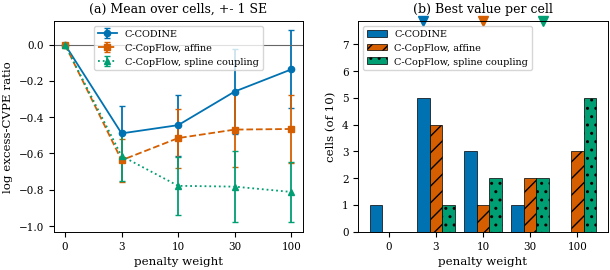

In [10]:
import figure_recipes as FR
FR.penalty_calibration(G, best, LAMBDAS, CHOSEN)

## Save: the weights read by the rest of the code

In [11]:
out = dict(penalty_codine=CHOSEN["C-CODINE"], penalty_flow_affine=CHOSEN["C-CopFlow, affine"],
           penalty_flow_spline=CHOSEN["C-CopFlow, spline coupling"], grid=list(LAMBDAS), delta=float(DELTA), delta_calibrated=float(DELTA_CAL),
           real_binned_ks=None if np.isnan(REAL_KS) else float(REAL_KS), delta_override=(_env is not None),
           smoke=bool(SMOKE), n_by_design=N_OF, schema_version=4,
           wd_codine=CHOSEN_WD["C-CODINE"], wd_flow_affine=CHOSEN_WD["C-CopFlow, affine"], wd_flow_spline=CHOSEN_WD["C-CopFlow, spline coupling"],
           wd_grid=list(WD_LIST), wd_mode=MODE_WD, lambda_mode=MODE_LAM, n_by_design_wd=N_OF_WD,
           one_se=ONE_SE, rule="lower median over the 10 cells (one per design, w-only variant of each group) of the argmin of the excess CVPE; weight decay first (penalty off), then lambda with those weight decays")
with open(ARTIFACT_DIR / "margin_penalty_calibrated.json", "w") as fh:
    json.dump(out, fh, indent=1)
save_artifact("penalty_calibration", long=LONG, best=best, summary=G.reset_index(), chosen=out,
              wd_long=WDLONG, wd_best=best_wd, wd_summary=G_WD.reset_index())
print("written:", ARTIFACT_DIR / "margin_penalty_calibrated.json", "| penalty:", out["penalty_codine"], out["penalty_flow_affine"], out["penalty_flow_spline"], "| weight decay:", out["wd_codine"], out["wd_flow_affine"], out["wd_flow_spline"])
print("Restart the kernel (or run NB04 in a new process) so that fold_pipeline reads the new weights.")

written: artifacts/margin_penalty_calibrated.json | penalty: 3.0 10.0 30.0 | weight decay: 0.001 0.01 0.01
Restart the kernel (or run NB04 in a new process) so that fold_pipeline reads the new weights.


## Table layout

In [12]:
RT.fit_all_tables()

[]